In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [56]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

In [57]:
train.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [58]:
train.shape, test.shape

((891, 12), (418, 11))

In [59]:
# PassengerId — идентификатор пассажира.
# Survived    — целевая переменная: 0 — не выжил, 1 — выжил; только в train.
# Pclass      — класс билета: 1 — первый, 2 — второй, 3 — третий.
# Name        — полное имя пассажира, включая обращение (Mr, Mrs, Miss и др.).
# Sex         — пол пассажира.
# Age         — возраст в годах; у младенцев может быть дробным.
# SibSp       — количество братьев, сестёр и супругов на борту.
# Parch       — количество родителей и детей на борту.
# Ticket      — номер билета.
# Fare        — стоимость билета.
# Cabin       — номер каюты.
# Embarked    — порт посадки: C — Cherbourg, Q — Queenstown, S — Southampton.

In [60]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [61]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [62]:
survived_count = pd.DataFrame({'count' : train['Survived'].value_counts(), 'percent' : round(train['Survived'].value_counts(normalize=True) * 100,2)})
print(survived_count) 
# Количество вышивших, погибших и процент

          count  percent
Survived                
0           549    61.62
1           342    38.38


In [63]:
train[train['Survived'] == 1]['Sex'].value_counts()
# Женщин выжило больше мужчин

Sex
female    233
male      109
Name: count, dtype: int64

In [64]:
train[train['Survived'] == 0]['Sex'].value_counts()
# Мужчин погибло сильно больше в кол-ве

Sex
male      468
female     81
Name: count, dtype: int64

In [65]:
round(train.groupby('Sex')['Survived'].mean()*100,2)
# Процент выживших мужчин и женщин внутри своего пола. 

Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

(array([ 54.,  46., 177., 169., 118.,  70.,  45.,  24.,   9.,   2.]),
 array([ 0.42 ,  8.378, 16.336, 24.294, 32.252, 40.21 , 48.168, 56.126,
        64.084, 72.042, 80.   ]),
 <BarContainer object of 10 artists>)

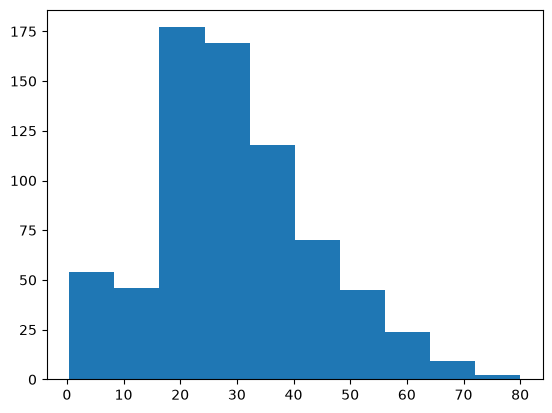

In [66]:
plt.hist(train['Age'].dropna())
# Наибольшее кол-во пассажиров в диапазоне 20-30 лет, 30-40 лет

(array([216.,   0.,   0.,   0.,   0., 184.,   0.,   0.,   0., 491.]),
 array([1. , 1.2, 1.4, 1.6, 1.8, 2. , 2.2, 2.4, 2.6, 2.8, 3. ]),
 <BarContainer object of 10 artists>)

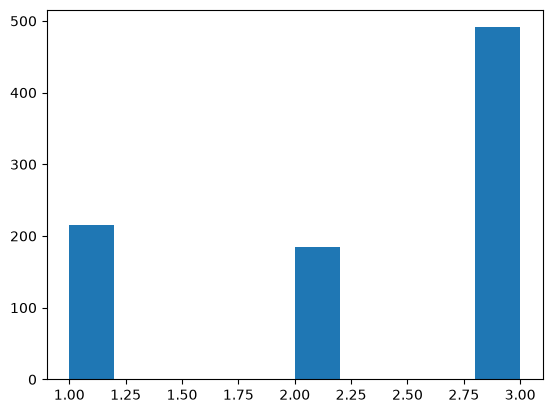

In [67]:
plt.hist(train['Pclass'].dropna())
# 3 класс самый часто встречающийся, далее 1 и далее 2

{'whiskers': [<matplotlib.lines.Line2D at 0x1b9265c74d0>,
 'caps': [<matplotlib.lines.Line2D at 0x1b9265c7750>,
 'boxes': [<matplotlib.lines.Line2D at 0x1b9265c7390>],
 'medians': [<matplotlib.lines.Line2D at 0x1b9265c79d0>],
 'fliers': [<matplotlib.lines.Line2D at 0x1b9265c7b10>],
 'means': []}

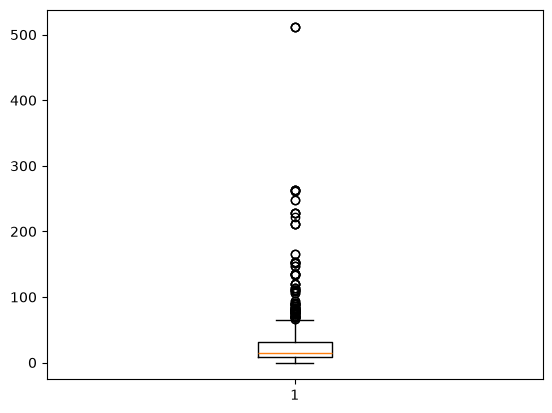

In [68]:
plt.boxplot(train['Fare'].dropna())
#Основная масса с билетами до 100 и до 200. Остальное выбросы

In [69]:
fare_groups = pd.cut(
    train["Fare"],
    bins=[0, 10, 30, 100, float("inf")],
    include_lowest=True,
)

train.groupby(fare_groups, observed=True)["Survived"].agg(
    passengers="count",
    survival_rate="mean",
)
# группировка по цене билета в диапазонах и кол-ву пассажиров сопоставляяем с выживаемостью. Видим что у самых бюджетных билетов меньше rate

,passengers,survival_rate
Fare,,
"(-0.001, 10.0]",336,0.199405
"(10.0, 30.0]",321,0.433022
"(30.0, 100.0]",181,0.535912
"(100.0, inf]",53,0.735849


In [70]:
round(train.groupby('Embarked')['Survived'].mean()*100,2)
# Процент выживших исходя из порта посадки. C выше, но это особо ни о чем не говорит по факту как соло фича

Embarked
C    55.36
Q    38.96
S    33.70
Name: Survived, dtype: float64

In [71]:
train.groupby("SibSp")["Survived"].agg(
    passengers="count",
    survival_rate="mean",
).round(3)
# у больших семей доля выживших ниже

,passengers,survival_rate
SibSp,,
0,608,0.345
1,209,0.536
2,28,0.464
3,16,0.250
4,18,0.167
5,5,0.000
8,7,0.000


In [72]:
train.groupby("Parch")["Survived"].agg(
    passengers="count",
    survival_rate="mean",
).round(3)
# с нулевым кол-вом родителей и детей процент выживаемости пониже

,passengers,survival_rate
Parch,,
0,678,0.344
1,118,0.551
2,80,0.500
3,5,0.600
4,4,0.000
5,5,0.200
6,1,0.000


In [73]:
features = [
    "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"
]
# PassengerId, Name, Ticket, Cabin пока отбрасываю, т.к. значения в основном там уникальные и пользы на оубчении пока не вижу

In [74]:
numeric_features = ["Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Pclass", "Sex", "Embarked"]

In [75]:
X = train[features].copy()
y = train['Survived']

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


In [ ]:
from sklearn.impute import SimpleImputer

In [ ]:
numeric_imputer = SimpleImputer(strategy="median")
categorical_imputer = SimpleImputer(strategy="most_frequent")

In [ ]:
from sklearn.compose import ColumnTransformer

In [ ]:
preprocessor = ColumnTransformer([
    ("numbers", numeric_imputer, numeric_features),
    ("categories", categorical_imputer, categorical_features),
])

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline([
    ("imputer", categorical_imputer),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

In [ ]:
preprocessor = ColumnTransformer([
    ("numbers", numeric_imputer, numeric_features),
    ("categories", categorical_pipeline, categorical_features),
])

In [ ]:
from sklearn.preprocessing import StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", numeric_imputer),
    ("scaler", StandardScaler()),
])

In [ ]:
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

In [ ]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

In [ ]:
print('Accuracy по 5 фолдам:', scores.round(4))
print(f'Mean accuracy: {scores.mean():.4f}')
print(f'std accuracy: {scores.std():.4f}')

In [ ]:
from pathlib import Path

results_path = Path("results.csv")
if results_path.exists():
    results = pd.read_csv(results_path)
else:
    results = pd.DataFrame(columns=["model", "accuracy_mean", "accuracy_std"])


def save_result(model_name, fold_scores):
    """Append a new experiment without overwriting any saved experiment."""
    global results
    current = pd.read_csv(results_path) if results_path.exists() else results.copy()
    if model_name in current["model"].values:
        results = current
        print(f"Already saved: {model_name}. Previous result kept. Use a new name for a new experiment.")
        return
    row = pd.DataFrame([{
        "model": model_name,
        "accuracy_mean": float(np.mean(fold_scores)),
        "accuracy_std": float(np.std(fold_scores)),
    }])
    results = pd.concat([current, row], ignore_index=True)
    results.to_csv(results_path, index=False)


In [ ]:
print("Accuracy by fold:", scores.round(4))
print(f"Mean accuracy: {scores.mean():.4f}")
print(f"Accuracy std: {scores.std():.4f}")
save_result('logistic_regression', scores)


In [ ]:
print(results)

In [ ]:
results.to_csv("results.csv", index=False)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])



In [ ]:
scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy", error_score="raise")

print("Accuracy by fold:", scores.round(4))
print(f"Mean accuracy: {scores.mean():.4f}")
print(f"Accuracy std: {scores.std():.4f}")
save_result('Random_forest_classifier', scores)


In [ ]:
print(results)

In [ ]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42,
        n_jobs=-1,
    )),
])

In [ ]:
scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy", error_score="raise")

print("Accuracy by fold:", scores.round(4))
print(f"Mean accuracy: {scores.mean():.4f}")
print(f"Accuracy std: {scores.std():.4f}")
save_result('Random_forest_depth5', scores)


In [ ]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1,
    )),
])

In [ ]:
scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy", error_score="raise")

print("Accuracy by fold:", scores.round(4))
print(f"Mean accuracy: {scores.mean():.4f}")
print(f"Accuracy std: {scores.std():.4f}")
save_result('Random_forest_leaf5', scores)


In [ ]:
print(results)

In [ ]:
from sklearn.tree import DecisionTreeClassifier

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42)),
])

In [ ]:
scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy", error_score="raise")

print("Accuracy by fold:", scores.round(4))
print(f"Mean accuracy: {scores.mean():.4f}")
print(f"Accuracy std: {scores.std():.4f}")
save_result('Desicion_tree', scores)


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1,
    )),
])

In [ ]:
scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy", error_score="raise")

print("Accuracy by fold:", scores.round(4))
print(f"Mean accuracy: {scores.mean():.4f}")
print(f"Accuracy std: {scores.std():.4f}")
save_result('KNN_neighbors5', scores)


In [ ]:
from xgboost import XGBClassifier

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=3,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
    )),
])

In [ ]:
scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy", error_score="raise")

print("Accuracy by fold:", scores.round(4))
print(f"Mean accuracy: {scores.mean():.4f}")
print(f"Accuracy std: {scores.std():.4f}")
save_result('XGB_dept3_lr0.03,estimators300', scores)


In [ ]:
print(results)

In [ ]:
from catboost import CatBoostClassifier

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", CatBoostClassifier(
        iterations=500,
        learning_rate=0.03,
        depth=4,
        random_seed=42,
        verbose=False,
        allow_writing_files=False,
    )),
])

In [ ]:
scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy", error_score="raise")

print("Accuracy by fold:", scores.round(4))
print(f"Mean accuracy: {scores.mean():.4f}")
print(f"Accuracy std: {scores.std():.4f}")
save_result('catboost_iter500,lr0,03,depth4', scores)


In [ ]:
from lightgbm import LGBMClassifier

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LGBMClassifier(
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=8,
        min_child_samples=20,
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
    )),
])

In [ ]:
scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy", error_score="raise")

print("Accuracy by fold:", scores.round(4))
print(f"Mean accuracy: {scores.mean():.4f}")
print(f"Accuracy std: {scores.std():.4f}")
save_result('LGBM', scores)


In [ ]:
print(results)

In [ ]:
from sklearn.ensemble import VotingClassifier

voting = VotingClassifier(
    estimators=[
        ("logreg", LogisticRegression(max_iter=1000)),
        ("forest", RandomForestClassifier(
            n_estimators=100,
            max_depth=5,
            random_state=42,
            n_jobs=-1,
        )),
        ("lightgbm", LGBMClassifier(
            n_estimators=300,
            learning_rate=0.03,
            num_leaves=8,
            min_child_samples=20,
            random_state=42,
            n_jobs=-1,
            verbosity=-1,
        )),
    ],
    voting="soft",
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", voting),
])

In [ ]:
scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy", error_score="raise")

print("Accuracy by fold:", scores.round(4))
print(f"Mean accuracy: {scores.mean():.4f}")
print(f"Accuracy std: {scores.std():.4f}")
save_result('voting_soft_logreg_randomforest_lgbm', scores)


In [ ]:
print(results)
# LGBM, catboost лучший результат на validation

In [ ]:
import torch

In [ ]:
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.base import clone


In [ ]:
train_idx, valid_idx = next(cv.split(X, y))

X_train = X.iloc[train_idx]
X_valid = X.iloc[valid_idx]

y_train = y.iloc[train_idx]
y_valid = y.iloc[valid_idx]

In [ ]:
dl_preprocessor = clone(preprocessor)
dl_preprocessor.set_params(
    numbers=clone(numeric_pipeline),
    categories__encoder__sparse_output=False,
)


In [ ]:
X_train_ready = dl_preprocessor.fit_transform(X_train)
X_valid_ready = dl_preprocessor.transform(X_valid)

print(X_train_ready.shape)
print(X_valid_ready.shape)

In [ ]:
X_train_tensor = torch.tensor(X_train_ready, dtype=torch.float32)
X_valid_tensor = torch.tensor(X_valid_ready, dtype=torch.float32)

y_train_tensor = torch.tensor(
    y_train.to_numpy(), dtype=torch.float32
).reshape(-1, 1)

y_valid_tensor = torch.tensor(
    y_valid.to_numpy(), dtype=torch.float32
).reshape(-1, 1)

In [ ]:
print(X_train_tensor.shape)
print(y_train_tensor.shape)

In [ ]:
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    generator=torch.Generator().manual_seed(42),
)


In [ ]:
print("Пассажиров в loader:", len(train_loader.dataset))
print("Обучающих строк:", len(train_idx))
print("Батчей:", len(train_loader))

In [ ]:
torch.manual_seed(42)
mlp = nn.Sequential(
    nn.Linear(X_train_tensor.shape[1], 32),
    nn.ReLU(),
    nn.Linear(32, 1),
)


In [ ]:
mlp(X_train_tensor).shape

In [ ]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(mlp.parameters(), lr=0.001)


In [ ]:
n_epochs = 600

for epoch in range(n_epochs):
    mlp.train()
    optimizer.zero_grad()

    logits = mlp(X_train_tensor)
    loss = loss_fn(logits, y_train_tensor)

    loss.backward()
    optimizer.step()

    # Проверка на валидации без обновления весов.
    mlp.eval()

    with torch.no_grad():
        valid_logits = mlp(X_valid_tensor)
        valid_loss = loss_fn(valid_logits, y_valid_tensor)

    if (epoch + 1) % 25 == 0:
        print(
            f"Эпоха {epoch + 1}: "
            f"train loss = {loss.item():.4f}, "
            f"valid loss = {valid_loss.item():.4f}"
        )

In [ ]:
mlp.eval()

with torch.no_grad():
    train_logits = mlp(X_train_tensor)
    valid_logits = mlp(X_valid_tensor)

    train_predictions = (train_logits >= 0).float()
    valid_predictions = (valid_logits >= 0).float()

    train_accuracy = (
        train_predictions == y_train_tensor
    ).float().mean().item()

    valid_accuracy = (
        valid_predictions == y_valid_tensor
    ).float().mean().item()

print(f"Train accuracy: {train_accuracy:.4f}")
print(f"Valid accuracy: {valid_accuracy:.4f}")

# На одном фоле проверил 100, 300, 600 эпох. 600 лучше но возможно переобучение, прочекаем на 5 фолдах

In [ ]:
print(dl_preprocessor)

In [ ]:
print(dl_preprocessor)


## Продолжение после перезапуска ядра




In [108]:
import pandas as pd
import numpy as np
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
numeric_features = ["Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Pclass", "Sex", "Embarked"]
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
X = train[features].copy()
y = train["Survived"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

numeric_imputer = SimpleImputer(strategy="median")
categorical_imputer = SimpleImputer(strategy="most_frequent")
categorical_pipeline = Pipeline([
    ("imputer", categorical_imputer),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numbers", numeric_imputer, numeric_features),
    ("categories", categorical_pipeline, categorical_features),
])
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
dl_preprocessor = clone(preprocessor)
dl_preprocessor.set_params(
    numbers=clone(numeric_pipeline),
    categories__encoder__sparse_output=False,
)

from pathlib import Path

results_path = Path("results.csv")
if results_path.exists():
    results = pd.read_csv(results_path)
else:
    results = pd.DataFrame(columns=["model", "accuracy_mean", "accuracy_std"])


def save_result(model_name, fold_scores):
    """Append a new experiment without overwriting any saved experiment."""
    global results
    current = pd.read_csv(results_path) if results_path.exists() else results.copy()
    if model_name in current["model"].values:
        results = current
        print(f"Already saved: {model_name}. Previous result kept. Use a new name for a new experiment.")
        return
    row = pd.DataFrame([{
        "model": model_name,
        "accuracy_mean": float(np.mean(fold_scores)),
        "accuracy_std": float(np.std(fold_scores)),
    }])
    results = pd.concat([current, row], ignore_index=True)
    results.to_csv(results_path, index=False)

print(f"Ready: {len(X)} training rows, {len(results)} saved experiments. No training performed.")


Ready: 891 training rows, 19 saved experiments. No training performed.


In [111]:
mlp_scores = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X, y), start=1):
    fold_preprocessor = clone(dl_preprocessor)

    X_train_ready = fold_preprocessor.fit_transform(X.iloc[train_idx])
    X_valid_ready = fold_preprocessor.transform(X.iloc[valid_idx])

    X_train_tensor = torch.tensor(X_train_ready, dtype=torch.float32)
    X_valid_tensor = torch.tensor(X_valid_ready, dtype=torch.float32)

    y_train_tensor = torch.tensor(
        y.iloc[train_idx].to_numpy(), dtype=torch.float32
    ).reshape(-1, 1)

    y_valid_tensor = torch.tensor(
        y.iloc[valid_idx].to_numpy(), dtype=torch.float32
    ).reshape(-1, 1)

    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

    train_loader = DataLoader(
        train_dataset,
        batch_size=64,
        shuffle=True,
        generator=torch.Generator().manual_seed(42),
    )

    torch.manual_seed(42)

    mlp = nn.Sequential(
        nn.Linear(X_train_tensor.shape[1], 32),
        nn.ReLU(),
        nn.Linear(32, 1),
    )

    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.SGD(mlp.parameters(), lr=0.01, momentum=0.9)

    

    mlp.train()

    for epoch in range(100):
        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()

            logits = mlp(X_batch)
            loss = loss_fn(logits, y_batch)

            loss.backward()
            optimizer.step()

        

    mlp.eval()

    with torch.no_grad():
        predictions = (mlp(X_valid_tensor) >= 0).float()

        accuracy = (
            predictions == y_valid_tensor
        ).float().mean().item()

    mlp_scores.append(accuracy)
    print(f"Фолд {fold}: accuracy = {accuracy:.4f}")

mlp_scores = np.array(mlp_scores)

print(f"Средняя accuracy: {mlp_scores.mean():.4f}")
print(f"Стандартное отклонение: {mlp_scores.std():.4f}")

Фолд 1: accuracy = 0.8492
Фолд 2: accuracy = 0.8034
Фолд 3: accuracy = 0.8034
Фолд 4: accuracy = 0.8202
Фолд 5: accuracy = 0.8202
Средняя accuracy: 0.8193
Стандартное отклонение: 0.0167


In [112]:
save_result(
    "mlp_hidden32_sgd_lr0.01_momentum0.9_batch64_100epochs",
    mlp_scores,
)
results

,model,accuracy_mean,accuracy_std
0,logistic_regression,0.797991,0.013573
1,Random_forest_classifier,0.811424,0.020783
2,Random_forest_depth5,0.829377,0.017132
3,Random_forest_leaf5,0.820419,0.013382
4,Desicion_tree,0.785613,0.027302
5,KNN_neighbors5,0.711525,0.026592
6,"XGB_dept3_lr0.03,estimators300",0.826031,0.021074
7,"catboost_iter500,lr0,03,depth4",0.837242,0.019605
8,LGBM,0.837248,0.018569
9,voting_soft_logreg_randomforest_lgbm,0.832747,0.014195
